In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# Upload the Excel dataset in Google Colab
from google.colab import files
uploaded = files.upload()

df = pd.read_excel(next(iter(uploaded)))

features = ['Feature_1', 'Feature_2', 'Feature_3',
            'Feature_4', 'Feature_5', 'Feature_6']

X = df[features]
y = df['Category']

print(df.head(10))
print("Shape:", df.shape)
print(y.value_counts())

Saving PCA_Lab_Dataset_FINAL.xlsx to PCA_Lab_Dataset_FINAL (1).xlsx
   Record_ID  Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  \
0          1     69.394     41.410     92.474    0.68929    249.600   
1          2     57.517     39.418    117.805    0.46986    201.941   
2          3     25.073     15.761    100.371    0.33674    150.365   
3          4     58.366     47.963    156.155    0.41419    177.654   
4          5     32.593     21.135    103.053    0.34925    160.427   
5          6     49.044     31.771    114.819    0.47169    190.987   
6          7     63.622     37.318     95.499    0.60597    232.762   
7          8     50.506     39.531    122.114    0.42179    190.326   
8          9     34.448     18.576     97.578    0.36463    169.289   
9         10     66.558     44.519     97.723    0.66130    249.348   

   Feature_6 Category  
0     72.812  Class_3  
1     89.406  Class_2  
2     67.317  Class_1  
3    107.031  Class_2  
4     70.200  Class_1  
5     

Mean: [-6.21724894e-17 -1.30266168e-16 -5.03301104e-16  4.13002965e-16
  4.39648318e-16  4.97379915e-16]
Standard deviation: [1. 1. 1. 1. 1. 1.]


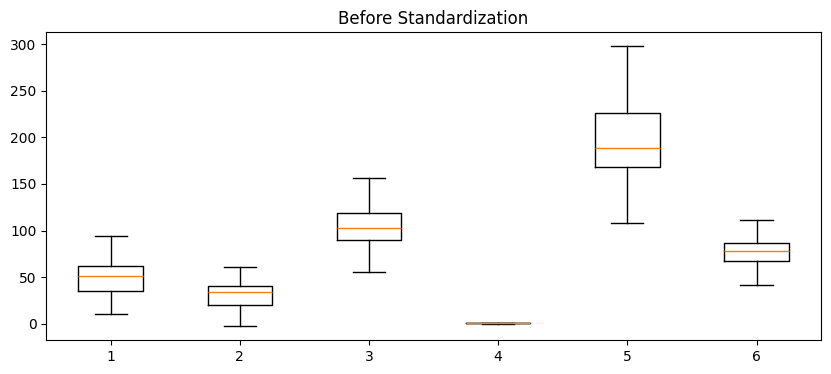

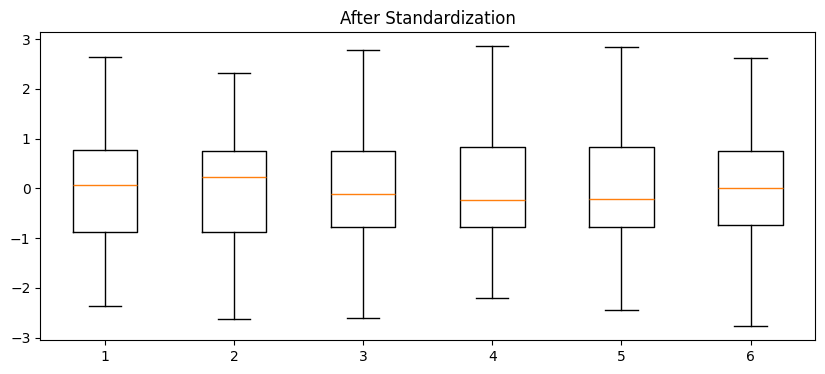

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean:", X_scaled.mean(axis=0))
print("Standard deviation:", X_scaled.std(axis=0))

plt.figure(figsize=(10, 4))
plt.boxplot(X.values)
plt.title("Before Standardization")
plt.show()

plt.figure(figsize=(10, 4))
plt.boxplot(X_scaled)
plt.title("After Standardization")
plt.show()

Covariance Matrix:
 [[ 1.00166945  0.92455172  0.30731579  0.86291321  0.90767403  0.57808454]
 [ 0.92455172  1.00166945  0.6208267   0.63452569  0.70431975  0.82271112]
 [ 0.30731579  0.6208267   1.00166945 -0.18236689 -0.09834907  0.93311299]
 [ 0.86291321  0.63452569 -0.18236689  1.00166945  0.98262367  0.12397555]
 [ 0.90767403  0.70431975 -0.09834907  0.98262367  1.00166945  0.21030544]
 [ 0.57808454  0.82271112  0.93311299  0.12397555  0.21030544  1.00166945]]


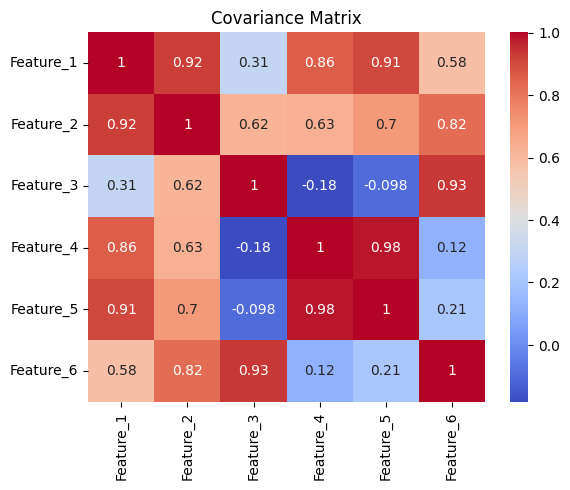

In [ ]:
cov = np.cov(X_scaled, rowvar=False)

print("Covariance Matrix:\n", cov)

sns.heatmap(cov, annot=True, cmap='coolwarm',
            xticklabels=features, yticklabels=features)
plt.title("Covariance Matrix")
plt.show()

In [ ]:
values, vectors = np.linalg.eigh(cov)

# Sort in descending order
idx = np.argsort(values)[::-1]
values = values[idx]
vectors = vectors[:, idx]

variance = values / values.sum()
cumulative = np.cumsum(variance)

table = pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(6)],
    'Eigenvalue': values,
    'Explained Variance': variance,
    'Cumulative Variance': cumulative
})

print(table)

print("Components needed for 95% variance:",
      np.argmax(cumulative >= 0.95) + 1)

    PC  Eigenvalue  Explained Variance  Cumulative Variance
0  PC1    3.933949            0.654565             0.654565
1  PC2    2.011532            0.334697             0.989262
2  PC3    0.022726            0.003781             0.993043
3  PC4    0.019487            0.003242             0.996286
4  PC5    0.012464            0.002074             0.998360
5  PC6    0.009859            0.001640             1.000000
Components needed for 95% variance: 2


In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("First 10 transformed observations:\n", X_pca[:10])
print("Explained variance:", pca.explained_variance_ratio_)
print("Manual variance:", variance[:2])

First 10 transformed observations:
 [[ 2.02223164 -1.89665312]
 [ 1.08903722  0.93879017]
 [-2.65496397  0.49772947]
 [ 1.93790732  3.44147609]
 [-1.95199662  0.55356292]
 [ 0.20163614  0.67249039]
 [ 1.38837181 -1.14655812]
 [ 0.67101898  1.46443885]
 [-1.99460715  0.06111995]
 [ 2.20480937 -1.32004199]]
Explained variance: [0.65456548 0.33469651]
Manual variance: [0.65456548 0.33469651]


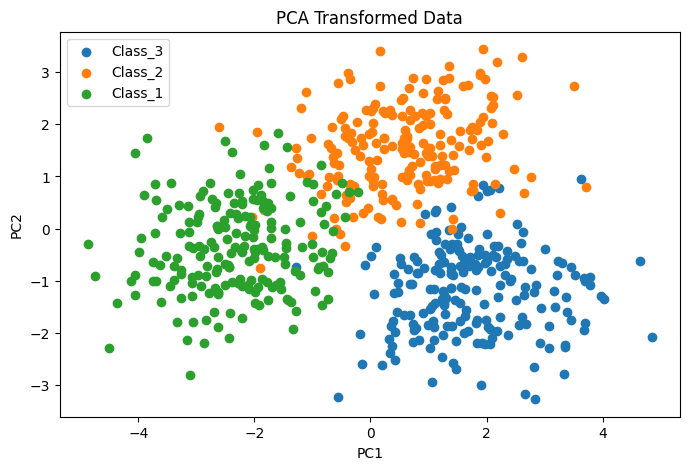

In [ ]:
plt.figure(figsize=(8, 5))

for category in y.unique():
    mask = y == category
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                label=category)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Transformed Data")
plt.legend()
plt.show()

                PC1       PC2
Feature_1  0.495709 -0.113647
Feature_2  0.491473  0.141288
Feature_3  0.230615  0.623617
Feature_4  0.394134 -0.433522
Feature_5  0.421360 -0.383461
Feature_6  0.355890  0.493193


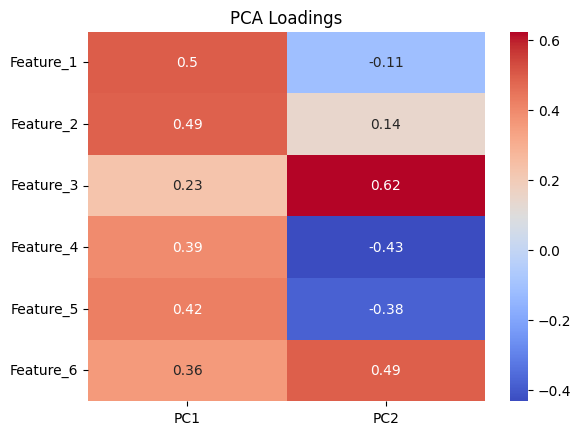

Largest contribution to PC1: Feature_1
Largest contribution to PC2: Feature_3


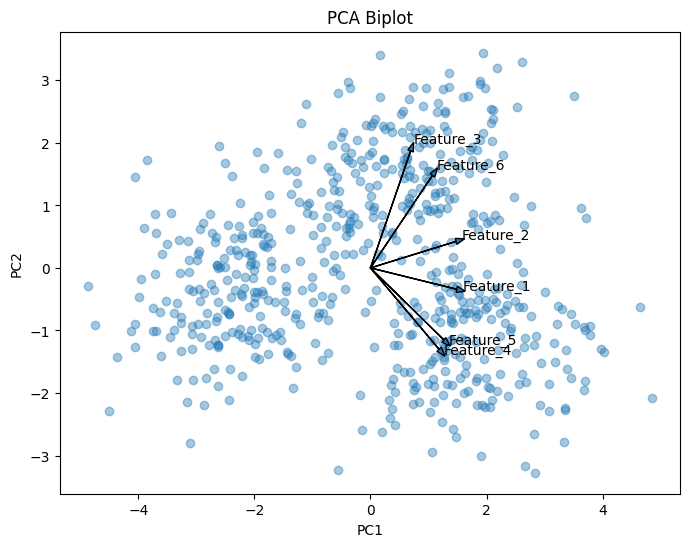

In [ ]:
loadings = pca.components_.T

print(pd.DataFrame(loadings,
                   index=features,
                   columns=['PC1', 'PC2']))

sns.heatmap(loadings, annot=True, cmap='coolwarm',
            xticklabels=['PC1', 'PC2'],
            yticklabels=features)
plt.title("PCA Loadings")
plt.show()

print("Largest contribution to PC1:",
      features[np.argmax(abs(loadings[:, 0]))])

print("Largest contribution to PC2:",
      features[np.argmax(abs(loadings[:, 1]))])

# Simple PCA biplot
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.4)

for i, feature in enumerate(features):
    plt.arrow(0, 0, loadings[i, 0]*3, loadings[i, 1]*3,
              head_width=0.1)
    plt.text(loadings[i, 0]*3.2, loadings[i, 1]*3.2, feature)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot")
plt.show()

In [ ]:
X_reconstructed = pca.inverse_transform(X_pca)

# Convert back to original scale
X_original_scale = scaler.inverse_transform(X_reconstructed)

print("Original observation:\n", X.iloc[0].values)
print("Reconstructed observation:\n", X_original_scale[0])

mse = np.mean((X.values - X_original_scale) ** 2)
print("Reconstruction MSE:", mse)

Original observation:
 [ 69.394    41.41     92.474     0.68929 249.6      72.812  ]
Reconstructed observation:
 [ 69.8871015   40.19652231  90.77833737   0.67972208 252.47433397
  74.63223393]
Reconstruction MSE: 3.293665957181426


Reconstruction errors: [np.float64(0.34543452312507605), np.float64(0.01073801224036837), np.float64(0.006956738946593853), np.float64(0.003714296973665277), np.float64(0.0016404728674713758), np.float64(1.9512446742300853e-31)]


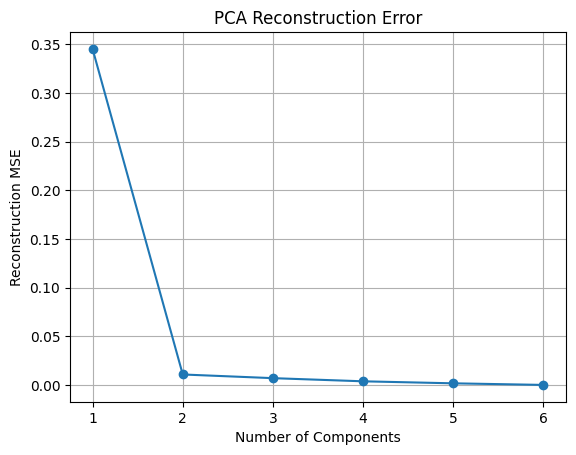

In [ ]:
errors = []

for n in range(1, 7):
    model = PCA(n_components=n)
    transformed = model.fit_transform(X_scaled)
    reconstructed = model.inverse_transform(transformed)

    error = np.mean((X_scaled - reconstructed) ** 2)
    errors.append(error)

print("Reconstruction errors:", errors)

plt.plot(range(1, 7), errors, marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Reconstruction MSE")
plt.title("PCA Reconstruction Error")
plt.grid()
plt.show()

Accuracy using original features: 0.9555555555555556
Accuracy using PCA features: 0.9388888888888889


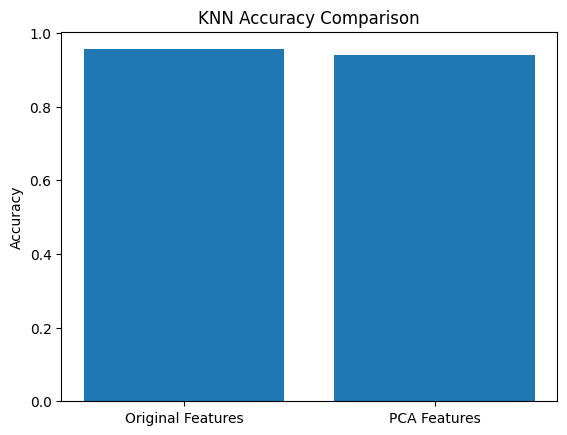

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# KNN using all six features
knn1 = make_pipeline(StandardScaler(),
                    KNeighborsClassifier(n_neighbors=5))
knn1.fit(X_train, y_train)
pred1 = knn1.predict(X_test)
acc1 = accuracy_score(y_test, pred1)

# KNN using two PCA components
knn2 = make_pipeline(
    StandardScaler(),
    PCA(n_components=2),
    KNeighborsClassifier(n_neighbors=5)
)
knn2.fit(X_train, y_train)
pred2 = knn2.predict(X_test)
acc2 = accuracy_score(y_test, pred2)

print("Accuracy using original features:", acc1)
print("Accuracy using PCA features:", acc2)

plt.bar(['Original Features', 'PCA Features'], [acc1, acc2])
plt.ylabel("Accuracy")
plt.title("KNN Accuracy Comparison")
plt.show()

In [ ]:
print("Original features:", X.shape[1])
print("Reduced features:", 2)
print("Variance retained:", pca.explained_variance_ratio_.sum())
print("Reconstruction MSE:", mse)
print("Original KNN accuracy:", acc1)
print("PCA KNN accuracy:", acc2)

if acc2 > acc1:
    print("PCA improved classification accuracy.")
elif acc2 < acc1:
    print("PCA reduced classification accuracy.")
else:
    print("Both methods achieved equal accuracy.")

Original features: 6
Reduced features: 2
Variance retained: 0.9892619877596318
Reconstruction MSE: 3.293665957181426
Original KNN accuracy: 0.9555555555555556
PCA KNN accuracy: 0.9388888888888889
PCA reduced classification accuracy.
